In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn tensorflow

Cell 2 – Import required libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

Cell 3 – Read the dataset

In [3]:
df = pd.read_csv("Churn_Modelling.csv")

print("First 5 records:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

First 5 records:
   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113931.57       1  
3         93826.63       

Cell 4 – Data preprocessing

In [4]:
# Remove unnecessary columns
df.drop(
    columns=["RowNumber", "CustomerId", "Surname"],
    inplace=True,
    errors="ignore"
)

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Remove missing values
df.dropna(inplace=True)

# Convert categorical columns into numerical columns
df = pd.get_dummies(
    df,
    columns=["Geography", "Gender"],
    drop_first=True,
    dtype=int
)

print("Dataset after preprocessing:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

Dataset after preprocessing:
   CreditScore  Age  Tenure    Balance  NumOfProducts  HasCrCard  \
0          619   42       2       0.00              1          1   
1          608   41       1   83807.86              1          0   
2          502   42       8  159660.80              3          1   
3          699   39       1       0.00              2          0   
4          850   43       2  125510.82              1          1   

   IsActiveMember  EstimatedSalary  Exited  Geography_Germany  \
0               1        101348.88       1                  0   
1               1        112542.58       0                  0   
2               0        113931.57       1                  0   
3               0         93826.63       0                  0   
4               1         79084.10       0                  0   

   Geography_Spain  Gender_Male  
0                0            0  
1                1            0  
2                0            0  
3                0            0  
4

Cell 5 – Separate features and target variable

In [5]:
# Independent features
X = df.drop("Exited", axis=1)

# Dependent target
y = df["Exited"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

print("\nTarget Distribution:")
print(y.value_counts())

Features:
   CreditScore  Age  Tenure    Balance  NumOfProducts  HasCrCard  \
0          619   42       2       0.00              1          1   
1          608   41       1   83807.86              1          0   
2          502   42       8  159660.80              3          1   
3          699   39       1       0.00              2          0   
4          850   43       2  125510.82              1          1   

   IsActiveMember  EstimatedSalary  Geography_Germany  Geography_Spain  \
0               1        101348.88                  0                0   
1               1        112542.58                  0                1   
2               0        113931.57                  0                0   
3               0         93826.63                  0                0   
4               1         79084.10                  0                1   

   Gender_Male  
0            0  
1            0  
2            0  
3            0  
4            0  

Target:
0    1
1    0
2    1
3   

Cell 6 – Split dataset into training and testing sets

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (8000, 11)
Testing Data: (2000, 11)


Cell 7 – Normalize the training and testing data

In [7]:
scaler = StandardScaler()

# Fit on training data and transform
X_train = scaler.fit_transform(X_train)

# Transform testing data
X_test = scaler.transform(X_test)

print("Normalization Completed!")

Normalization Completed!


Cell 8 – Initialize and build the basic neural network model

In [8]:
# Initialize ANN model
model = Sequential()

# Input layer and first hidden layer
model.add(Dense(16, activation="relu",
                input_shape=(X_train.shape[1],)))

# Second hidden layer
model.add(Dense(8, activation="relu"))

# Output layer
model.add(Dense(1, activation="sigmoid"))

# Compile model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display model structure
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 337 (1.32 KB)

 Trainable params: 337 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

Cell 9 – Train the basic model

In [9]:
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7917 - loss: 0.5066 - val_accuracy: 0.8062 - val_loss: 0.4391
Epoch 2/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8114 - loss: 0.4290 - val_accuracy: 0.8281 - val_loss: 0.4212
Epoch 3/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8231 - loss: 0.4120 - val_accuracy: 0.8388 - val_loss: 0.4070
Epoch 4/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8297 - loss: 0.3990 - val_accuracy: 0.8475 - val_loss: 0.3929
Epoch 5/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8380 - loss: 0.3864 - val_accuracy: 0.8500 - val_loss: 0.3769
Epoch 6/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8439 - loss: 0.3744 - val_accuracy: 0.8569 - val_loss: 0.3652
Epoch 7/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8475 - loss: 0.3653 - val_accuracy: 0.8650 - val_loss: 0.3548
Epoch 8/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8498 - loss: 0.3591 - val_accuracy: 0.

Cell 10 – Evaluate the basic model

In [10]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Basic Model Accuracy:", accuracy * 100, "%")
print("Basic Model Loss:", loss)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8635 - loss: 0.3424
Basic Model Accuracy: 86.34999990463257 %
Basic Model Loss: 0.3424171805381775


Cell 11 – Identify points of improvement
The basic model can be improved using the following techniques:
1. Dropout: Prevents overfitting by randomly disabling some neurons during training.
2. Early Stopping: Stops training when validation loss stops improving.
3. Class Weight: Handles imbalanced data because fewer customers leave the bank than stay.
4. More epochs: Allows the model to learn better patterns.
We will implement these improvements in a new neural network model.

Cell 12 – Build the improved neural network model

In [11]:
# Initialize improved model
improved_model = Sequential()

# Input and hidden layer
improved_model.add(Dense(
    32,
    activation="relu",
    input_shape=(X_train.shape[1],)
))

# Dropout layer
improved_model.add(Dropout(0.3))

# Second hidden layer
improved_model.add(Dense(16, activation="relu"))

# Output layer
improved_model.add(Dense(1, activation="sigmoid"))

# Compile model
improved_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

improved_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 929 (3.63 KB)

 Trainable params: 929 (3.63 KB)

 Non-trainable params: 0 (0.00 B)

Cell 13 – Implement Early Stopping and class weighting

In [12]:
# Early stopping
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Calculate class weights
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class Weights:", class_weights)

Class Weights: {np.int64(0): np.float64(0.6279434850863422), np.int64(1): np.float64(2.4539877300613497)}


Cell 14 – Train the improved model

In [13]:
history2 = improved_model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    class_weight=class_weights,
    verbose=1
)

print("Improved Model Training Completed!")

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6009 - loss: 0.6458 - val_accuracy: 0.6681 - val_loss: 0.6325
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6969 - loss: 0.5915 - val_accuracy: 0.7169 - val_loss: 0.5803
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7116 - loss: 0.5739 - val_accuracy: 0.6963 - val_loss: 0.5898
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7195 - loss: 0.5572 - val_accuracy: 0.7119 - val_loss: 0.5524
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7222 - loss: 0.5491 - val_accuracy: 0.7094 - val_loss: 0.5512
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7292 - loss: 0.5381 - val_accuracy: 0.7306 - val_loss: 0.5203
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7322 - loss: 0.5253 - val_accuracy: 0.7300 - val_loss: 0.5114
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7405 - loss: 0.5181 - val_accuracy: 0.

Cell 15 – Plot training and validation accuracy

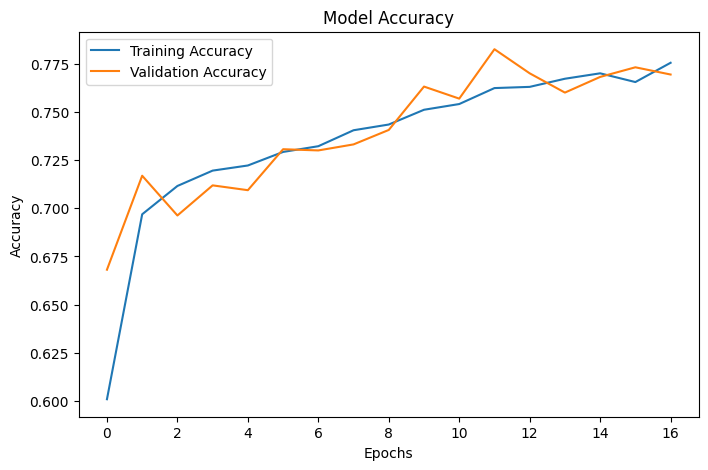

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(history2.history["accuracy"], label="Training Accuracy")
plt.plot(history2.history["val_accuracy"], label="Validation Accuracy")

plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()
plt.show()

Cell 16 – Predict customer churn

In [15]:
# Predict probabilities
y_pred_prob = improved_model.predict(X_test)

# Convert probabilities into binary classes
y_pred = (y_pred_prob > 0.5).astype(int)

print("Predicted Values:")
print(y_pred[:10].flatten())

print("\nActual Values:")
print(y_test.iloc[:10].values)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Predicted Values:
[0 0 0 0 0 1 0 1 1 0]

Actual Values:
[0 0 0 0 0 0 0 0 0 0]


Cell 17 – Print accuracy score

In [16]:
accuracy = accuracy_score(y_test, y_pred)

print("Improved Model Accuracy:", accuracy * 100, "%")

Improved Model Accuracy: 77.64999999999999 %


Cell 18 – Print confusion matrix

Confusion Matrix:
[[1237  356]
 [  91  316]]


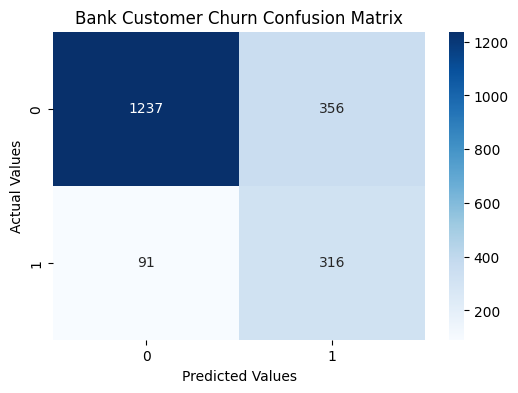

In [17]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Bank Customer Churn Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

Cell 19 – Classification report (additional evaluation)

In [18]:
print("Classification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Not Churned", "Churned"]
    )
)

Classification Report:
              precision    recall  f1-score   support

 Not Churned       0.93      0.78      0.85      1593
     Churned       0.47      0.78      0.59       407

    accuracy                           0.78      2000
   macro avg       0.70      0.78      0.72      2000
weighted avg       0.84      0.78      0.79      2000

